# How path construction changes performance estimates

A bagged fit averages predicted probabilities from repeated fits inside each combinatorial split:

$$
\widehat p_s(x)=\frac{1}{B}\sum_{b=1}^{B}\widehat p_{s,b}(x).
$$

Here, $s$ identifies a combinatorial split, $B$ is the number of fitted members, $\widehat p_{s,b}(x)$ is member $b$'s predicted probability for input $x$, and $\widehat p_s(x)$ is their average.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from itertools import combinations
from math import comb
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.backtest.validation import AdaptiveCombinatorialPurged, BaggedCombinatorialPurged, CombinatorialPurged, PurgedKFold

FIGURES = ROOT / "outputs" / "figures" / "17_combinatorial_purged_cross_validation"
TABLES = ROOT / "outputs" / "tables" / "17_combinatorial_purged_cross_validation"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

minute_data = raw.set_index("time")
bars = pd.DataFrame({
    "Close": minute_data["close"].resample("15min").last(),
    "Volume": minute_data["volume"].resample("15min").sum(),
    "Quote volume": minute_data["quote_volume"].resample("15min").sum(),
    "Trades": minute_data["trades"].resample("15min").sum(),
}).dropna()
log_close = np.log(bars["Close"])
one_bar_return = log_close.diff()
feature_frame = pd.DataFrame({
    "Previous return": one_bar_return.shift(1),
    "One-hour return": log_close.diff(4).shift(1),
    "Past volatility": one_bar_return.shift(1).rolling(16).std(),
    "Log volume change": np.log1p(bars["Volume"]).diff().shift(1),
    "Log quote-volume change": np.log1p(bars["Quote volume"]).diff().shift(1),
    "Log trade-count change": np.log1p(bars["Trades"]).diff().shift(1),
})
label_horizon = 8
forward_return = (log_close.shift(-label_horizon) - log_close).rename("Forward return")
direction = forward_return.gt(0).where(forward_return.notna()).astype("Int64").rename("Direction")
end_time = bars.index.to_series().shift(-label_horizon).rename("End time")
public_frame = pd.concat([feature_frame, direction, forward_return, end_time], axis=1).dropna()
public_x = public_frame[feature_frame.columns].astype(float)
public_y = public_frame["Direction"].astype(int)
event_times = public_frame["End time"]
external_feature = public_x["Past volatility"].copy()

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def path_number(name):
    return int(name.rsplit(" ", 1)[1])

def score_path_predictions(method, predictions):
    records = []
    for name in sorted(predictions, key=path_number):
        values = np.asarray(predictions[name]).reshape(-1)
        records.append({
            "Method": method,
            "Path": path_number(name),
            "Predictions": len(values),
            "Correct predictions": int(np.sum(values == public_y.to_numpy())),
            "Accuracy": accuracy_score(public_y, values),
            "Positive prediction share": float(np.mean(values == 1)),
        })
    return pd.DataFrame(records)

class ScaledLogisticRegression(ClassifierMixin, BaseEstimator):
    def __init__(self, max_iter=1000, random_state=15):
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, data, labels, sample_weight=None):
        self.scaler_ = StandardScaler().fit(data)
        transformed = self.scaler_.transform(data)
        self.model_ = LogisticRegression(max_iter=self.max_iter, solver="lbfgs", random_state=self.random_state)
        self.model_.fit(transformed, labels, sample_weight=sample_weight)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, data):
        return self.model_.predict(self.scaler_.transform(data))

    def predict_proba(self, data):
        return self.model_.predict_proba(self.scaler_.transform(data))

def overlap_count(train_indices, test_indices, times):
    allowed = PurgedKFold.filtered_training_indices_with_embargo(times, times.iloc[test_indices], embargo_fraction=0, continous_test_times=False)
    allowed_positions = set(times.index.get_indexer(allowed.index).tolist())
    return sum(int(int(index) not in allowed_positions) for index in train_indices)

state_colors = ListedColormap([palette["muted"], palette["cyan"], palette["rose"], palette["amber"]])
state_norm = BoundaryNorm(np.arange(-0.5, 4.5, 1), state_colors.N)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Public Path Predictions

,Method,Path,Predictions,Correct predictions,Accuracy,Positive prediction share
0,Standard CPCV,1,2951,1454,0.492714,0.408336
1,Standard CPCV,2,2951,1505,0.509997,0.678414
2,Standard CPCV,3,2951,1476,0.500169,0.808878
3,Standard CPCV,4,2951,1448,0.490681,0.849543
4,Standard CPCV,5,2951,1472,0.498814,0.755337


,Method,Path,Predictions,Correct predictions,Accuracy,Positive prediction share
0,Standard CPCV,1,2951,1454,0.492714,0.408336
1,Standard CPCV,2,2951,1505,0.509997,0.678414
2,Standard CPCV,3,2951,1476,0.500169,0.808878
3,Standard CPCV,4,2951,1448,0.490681,0.849543
4,Standard CPCV,5,2951,1472,0.498814,0.755337
5,Bagged CPCV,1,2951,1458,0.494070,0.383938
6,Bagged CPCV,2,2951,1504,0.509658,0.663165
7,Bagged CPCV,3,2951,1471,0.498475,0.786852
8,Bagged CPCV,4,2951,1468,0.497458,0.833955
9,Bagged CPCV,5,2951,1473,0.499153,0.732633


,Method,Mean accuracy,Accuracy spread,Minimum accuracy,Maximum accuracy
0,Standard CPCV,0.498475,0.007577,0.490681,0.509997
1,Bagged CPCV,0.499763,0.005866,0.494070,0.509658
2,Adaptive CPCV,0.494680,0.005606,0.488987,0.502880


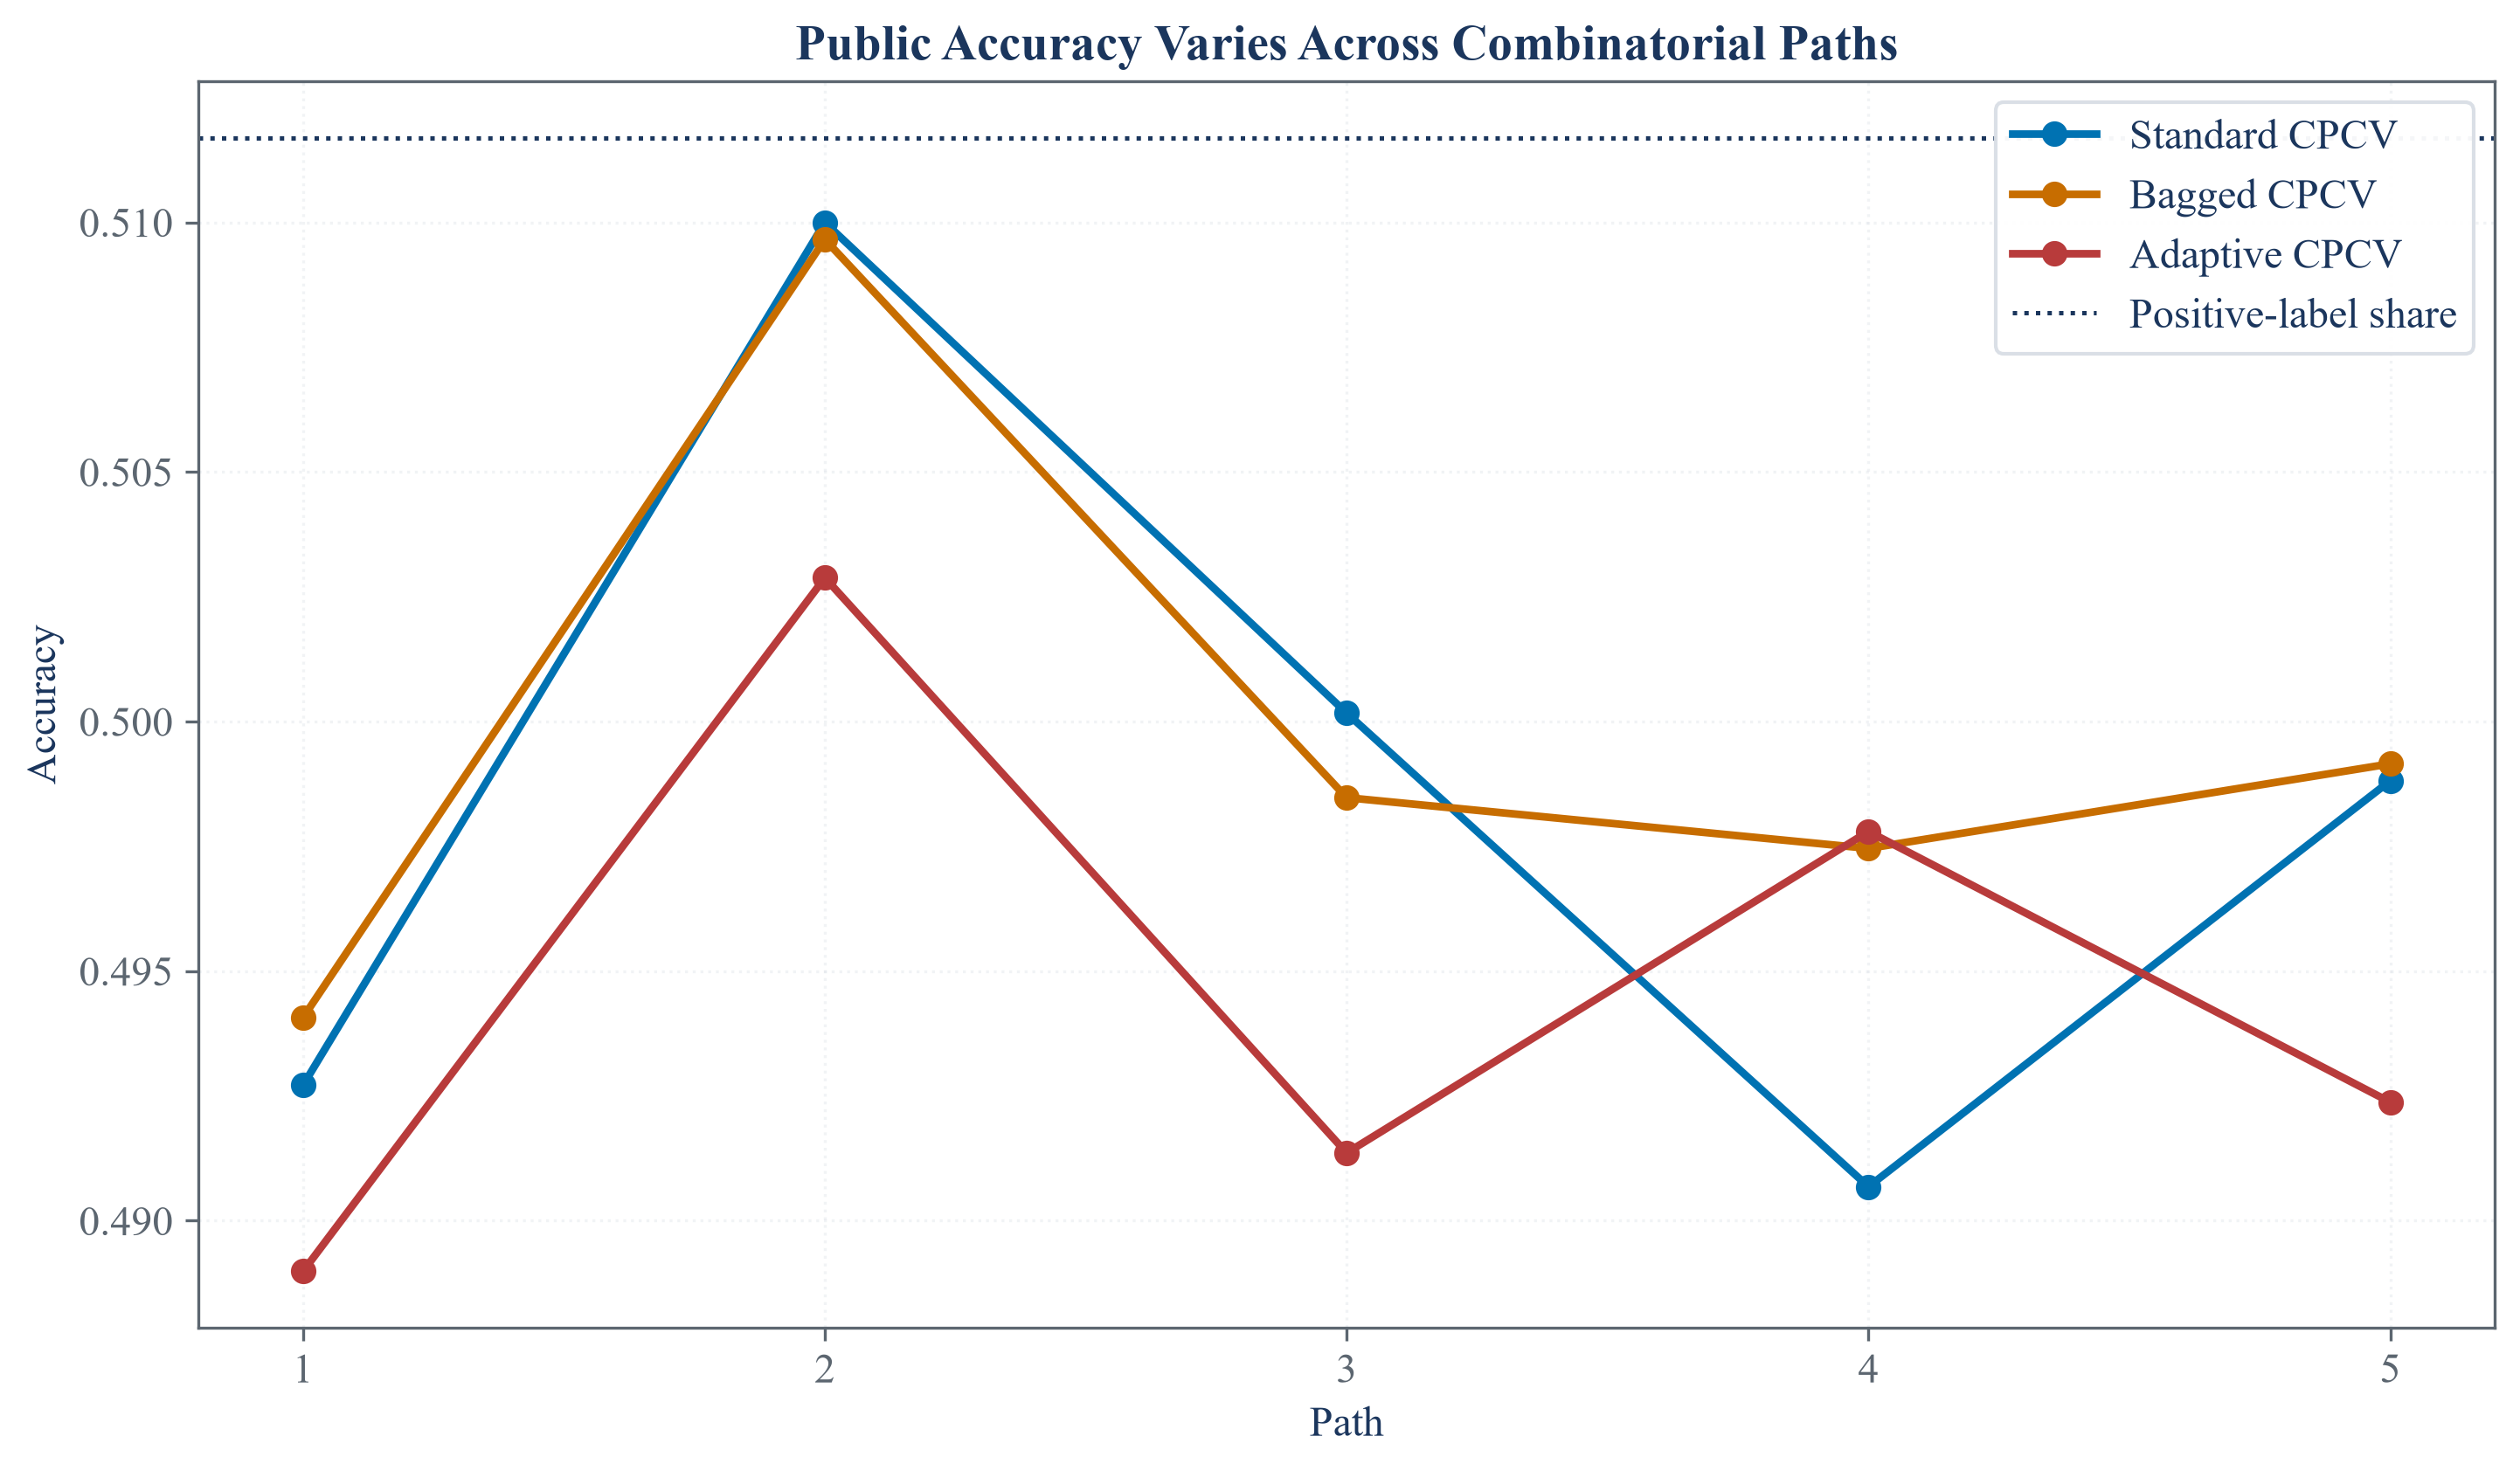

In [2]:
n_groups = 6
n_test_groups = 2
embargo_fraction = 0.01
base_estimator = ScaledLogisticRegression(max_iter=1000, random_state=15)
standard_validator = CombinatorialPurged(n_splits=n_groups, n_test_groups=n_test_groups, times=event_times, embargo=embargo_fraction)
bagged_validator = BaggedCombinatorialPurged(n_splits=n_groups, n_test_groups=n_test_groups, times=event_times, embargo=embargo_fraction, classifier=True, n_estimators=12, random_state=15)
adaptive_validator = AdaptiveCombinatorialPurged(n_splits=n_groups, n_test_groups=n_test_groups, times=event_times, embargo=embargo_fraction, n_subsplits=3, external_feature=external_feature, lower_quantile=0.25, upper_quantile=0.75, subtract_border_adjustments=True)

standard_predictions = standard_validator.backtest_predictions(base_estimator, public_x, public_y, n_jobs=1)
bagged_predictions = bagged_validator.backtest_predictions(base_estimator, public_x, public_y, n_jobs=1)
adaptive_predictions = adaptive_validator.backtest_predictions(base_estimator, public_x, public_y, n_jobs=1)

standard_path_accuracy = score_path_predictions("Standard CPCV", standard_predictions)
bagged_path_accuracy = score_path_predictions("Bagged CPCV", bagged_predictions)
adaptive_path_accuracy = score_path_predictions("Adaptive CPCV", adaptive_predictions)
method_path_accuracy = pd.concat([standard_path_accuracy, bagged_path_accuracy, adaptive_path_accuracy], ignore_index=True)
method_accuracy_summary = method_path_accuracy.groupby("Method", sort=False)["Accuracy"].agg(["mean", "std", "min", "max"]).reset_index()
method_accuracy_summary.columns = ["Method", "Mean accuracy", "Accuracy spread", "Minimum accuracy", "Maximum accuracy"]

save_table(standard_path_accuracy, "standard_path_accuracy", "Accuracy and prediction balance across the five standard public-data paths.", "tab:chapter15-standard-path-accuracy", fit=True)
save_table(method_path_accuracy, "method_path_accuracy", "Path-level public-data results for standard, bagged, and adaptive combinatorial validation.", "tab:chapter15-method-path-accuracy", fit=True)
save_table(method_accuracy_summary, "method_accuracy_summary", "Summary of public-data accuracy across five paths for each combinatorial method.", "tab:chapter15-method-accuracy-summary", fit=True)
display(standard_path_accuracy)
display(method_path_accuracy)
display(method_accuracy_summary)

figure, axis = plt.subplots(figsize=(9.5, 5.5), constrained_layout=True)
method_colors = {"Standard CPCV": palette["cyan"], "Bagged CPCV": palette["amber"], "Adaptive CPCV": palette["rose"]}
for method, color in method_colors.items():
    current = method_path_accuracy[method_path_accuracy["Method"] == method]
    axis.plot(current["Path"], current["Accuracy"], marker="o", linewidth=2.1, color=color, label=method)
axis.axhline(public_y.mean(), color=palette["text"], linestyle=":", linewidth=1.2, label="Positive-label share")
axis.set_title("Public Accuracy Varies Across Combinatorial Paths")
axis.set_xlabel("Path")
axis.set_ylabel("Accuracy")
axis.set_xticks(np.arange(1, 6))
axis.grid(alpha=0.35)
axis.legend()
figure.savefig(FIGURES / "method_path_accuracy.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "method_path_accuracy.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "method_path_accuracy.png")))
plt.close(figure)

## Bagging Within Each Split

A class prediction is obtained by thresholding the averaged probability:

$$
\widehat y_s(x)=\mathbf 1\!\left\{\widehat p_s(x)\geq\frac12\right\}.
$$

Here, $\widehat y_s(x)$ is the predicted class, $\widehat p_s(x)$ is the bagged probability for split $s$, $\tfrac12$ is the classification threshold, and $\mathbf 1\{\cdot\}$ is the indicator function.

## Moving Group Boundaries

The released adaptive rule moves a candidate boundary by one small block according to an external feature:

$$
b_j^*=b_j-\delta_j,
\qquad
\delta_j=
\begin{cases}
-1,&z_{b_j}<q_L,\\
0,&q_L\leq z_{b_j}\leq q_U,\\
1,&z_{b_j}>q_U.
\end{cases}
$$

Here, $b_j$ is candidate boundary $j$ measured in small blocks, $b_j^*$ is its adjusted position, $z_{b_j}$ is the external feature at that boundary, $q_L$ and $q_U$ are its lower and upper quantiles, and $\delta_j$ is the one-block adjustment used by the selected direction rule.

,Group,Standard observations,Adaptive observations,Standard begins,Adaptive begins,Adaptive volatility mean
0,1,492,328,2021-01-01 04:15:00,2021-01-01 04:15:00,0.005800
1,2,492,492,2021-01-06 07:15:00,2021-01-04 14:15:00,0.007374
2,3,492,656,2021-01-11 10:15:00,2021-01-09 17:15:00,0.008917
3,4,492,328,2021-01-16 13:15:00,2021-01-16 13:15:00,0.005392
4,5,492,656,2021-01-21 16:15:00,2021-01-19 23:15:00,0.005800
5,6,491,491,2021-01-26 19:15:00,2021-01-26 19:15:00,0.006878


,Method,Groups,Test groups,Splits,Paths,Distinct group sizes,Fitted members per split
0,Standard CPCV,6,2,15,5,2,1
1,Bagged CPCV,6,2,15,5,2,12
2,Adaptive CPCV,6,2,15,5,4,1


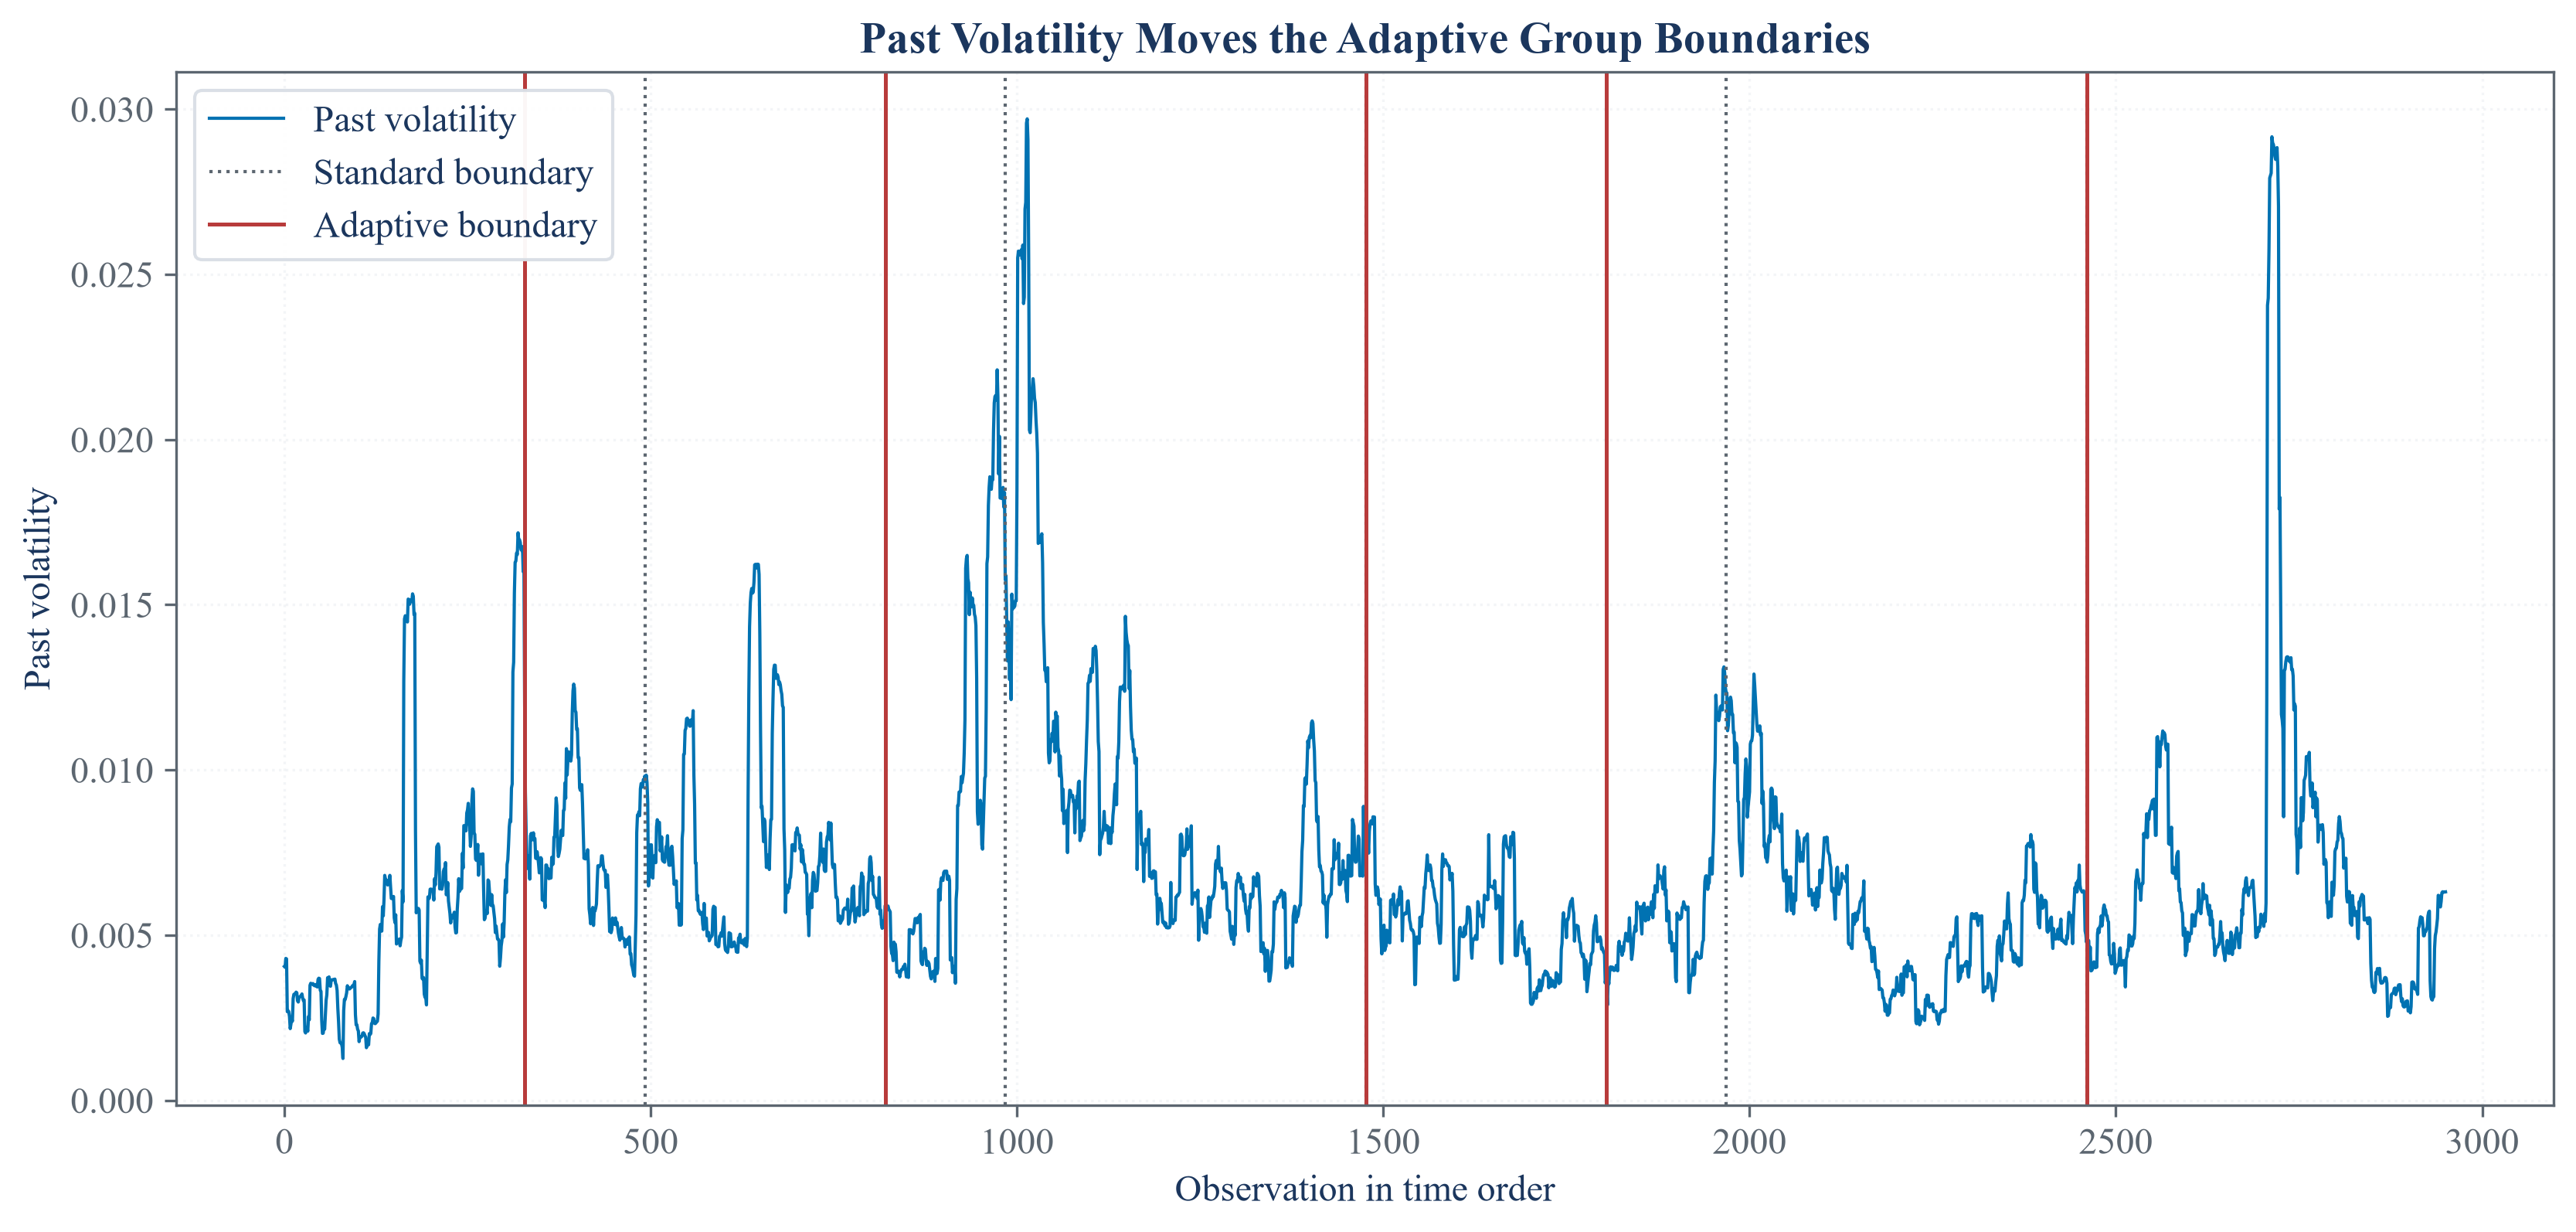

In [3]:
standard_segments = standard_validator._get_split_segments(public_x)
adaptive_segments = adaptive_validator._get_split_segments(public_x, external_feature)
adaptive_records = []
for group, (standard_segment, adaptive_segment) in enumerate(zip(standard_segments, adaptive_segments), start=1):
    adaptive_records.append({
        "Group": group,
        "Standard observations": len(standard_segment),
        "Adaptive observations": len(adaptive_segment),
        "Standard begins": str(public_x.index[standard_segment[0]]),
        "Adaptive begins": str(public_x.index[adaptive_segment[0]]),
        "Adaptive volatility mean": float(external_feature.iloc[adaptive_segment].mean()),
    })
adaptive_group_summary = pd.DataFrame(adaptive_records)
save_table(adaptive_group_summary, "adaptive_group_summary", "Standard and volatility-adjusted group sizes on the public data.", "tab:chapter15-adaptive-group-summary", fit=True)
display(adaptive_group_summary)

method_structure_summary = pd.DataFrame({
    "Method": ["Standard CPCV", "Bagged CPCV", "Adaptive CPCV"],
    "Groups": [n_groups, n_groups, n_groups],
    "Test groups": [n_test_groups, n_test_groups, n_test_groups],
    "Splits": [standard_validator.get_n_splits(), bagged_validator.get_n_splits(), adaptive_validator.get_n_splits()],
    "Paths": [len(standard_predictions), len(bagged_predictions), len(adaptive_predictions)],
    "Distinct group sizes": [len(set(map(len, standard_segments))), len(set(map(len, standard_segments))), len(set(map(len, adaptive_segments)))],
    "Fitted members per split": [1, bagged_validator.n_estimators, 1],
})
save_table(method_structure_summary, "method_structure_summary", "Structural comparison of the three released combinatorial methods used in the public experiment.", "tab:chapter15-method-structure-summary", fit=True)
display(method_structure_summary)

figure, axis = plt.subplots(figsize=(11.0, 5.2), constrained_layout=True)
axis.plot(np.arange(len(external_feature)), external_feature.to_numpy(), color=palette["cyan"], linewidth=1.0, label="Past volatility")
for index, segment in enumerate(standard_segments[1:], start=1):
    axis.axvline(segment[0], color=palette["muted"], linestyle=":", linewidth=1.0, label="Standard boundary" if index == 1 else None)
for index, segment in enumerate(adaptive_segments[1:], start=1):
    axis.axvline(segment[0], color=palette["rose"], linestyle="-", linewidth=1.2, label="Adaptive boundary" if index == 1 else None)
axis.set_title("Past Volatility Moves the Adaptive Group Boundaries")
axis.set_xlabel("Observation in time order")
axis.set_ylabel("Past volatility")
axis.grid(alpha=0.30)
axis.legend()
figure.savefig(FIGURES / "adaptive_boundaries.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "adaptive_boundaries.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "adaptive_boundaries.png")))
plt.close(figure)

The reported mean and spread summarize the finite set of paths:

$$
\overline A_m=\frac{1}{\varphi}\sum_{p=1}^{\varphi}A_{m,p},
\qquad
s_m=\sqrt{\frac{1}{\varphi-1}\sum_{p=1}^{\varphi}(A_{m,p}-\overline A_m)^2}.
$$

Here, $m$ identifies a validation method, $p$ identifies a path, $\varphi$ is the number of paths, $A_{m,p}$ is path accuracy, $\overline A_m$ is mean path accuracy, and $s_m$ is its sample spread. These quantities describe this public sample and do not establish that one method is generally best.

## Tests

In [4]:
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(standard_predictions) == 5
assert len(bagged_predictions) == 5
assert len(adaptive_predictions) == 5
assert all(len(values) == len(public_x) for values in standard_predictions.values())
assert all(len(values) == len(public_x) for values in bagged_predictions.values())
assert all(len(values) == len(public_x) for values in adaptive_predictions.values())
assert all(np.isin(values, [0, 1]).all() for values in standard_predictions.values())
assert all(np.isin(values, [0, 1]).all() for values in bagged_predictions.values())
assert all(np.isin(values, [0, 1]).all() for values in adaptive_predictions.values())
assert standard_path_accuracy.shape == (5, 6)
assert method_path_accuracy.shape == (15, 6)
assert method_accuracy_summary.shape == (3, 5)
assert method_path_accuracy["Accuracy"].between(0, 1).all()
assert sum(map(len, standard_segments)) == len(public_x)
assert sum(map(len, adaptive_segments)) == len(public_x)
assert len(set(map(len, standard_segments))) <= 2
assert len(set(map(len, adaptive_segments))) > 1
assert adaptive_group_summary.shape == (6, 6)
assert method_structure_summary.shape == (3, 7)
assert method_structure_summary["Splits"].eq(15).all()
assert method_structure_summary["Paths"].eq(5).all()
assert (FIGURES / "method_path_accuracy.pdf").is_file()
assert (FIGURES / "adaptive_boundaries.pdf").is_file()
assert (TABLES / "standard_path_accuracy.tex").is_file()
assert (TABLES / "method_path_accuracy.tex").is_file()
assert (TABLES / "method_accuracy_summary.tex").is_file()
assert (TABLES / "adaptive_group_summary.tex").is_file()
assert (TABLES / "method_structure_summary.tex").is_file()